In [ ]:
# IMPORTAÇÃO
!pip install tensorflow pandas numpy matplotlib scikit-learn
!pip install meteostat
import keras
from keras import layers
from keras import optimizers
import pandas as pd
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow.keras.utils import plot_model
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import MinMaxScaler
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.utils import plot_model
import os
from datetime import datetime
import psutil
import calendar
#from meteostat.model import Point, Daily

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.5/79.5 kB 3.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 93.8/93.8 kB 8.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.0/11.0 MB 62.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 506.5/506.5 kB 32.9 MB/s eta 0:00:00
  Attempting uninstall: pytz
    Found existing installation: pytz 2025.2
    Uninstalling pytz-2025.2:
      Successfully uninstalled pytz-2025.2
  Attempting uninstall: pandas
    Found existing installation: pandas 2.2.2
    Uninstalling pandas-2.2.2:
      Successfully uninstalled pandas-2.2.2
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.2, but you have pandas 3.0.5 which is incompatible.


In [ ]:
url = "https://raw.githubusercontent.com/devThalys/Previsao-de-Demanda/refs/heads/main/sucos_claujuices_jun2026.csv"
data = pd.read_csv(url, sep=',', engine='python', keep_default_na=False)
data.columns = data.columns.str.strip().str.lower()
data['sabor'] = data['sabor'].str.lower().str.strip()
print(data.columns)
print(data.head())

Index(['ano', 'mes', 'data_inicio', 'data_fim', 'temperatura', 'dias',
       'dias_de_semana', 'dias_uteis', 'dias_fim_semana', 'feriado',
       'sabor_novo', 'volume_ant', 'media_movel_3m', 'sabor', 'volume_l'],
      dtype='str')
    ano  mes data_inicio    data_fim temperatura  dias  dias_de_semana  \
0  2025    4  2025-04-01  2025-04-30      17,625    30              22   
1  2025    4  2025-04-01  2025-04-30      17,625    30              22   
2  2025    4  2025-04-01  2025-04-30      17,625    30              22   
3  2025    4  2025-04-01  2025-04-30      17,625    30              22   
4  2025    4  2025-04-01  2025-04-30      17,625    30              22   

   dias_uteis  dias_fim_semana  feriado  sabor_novo volume_ant media_movel_3m  \
0          20                8        2           1          0              0   
1          20                8        2           1          0              0   
2          20                8        2           1          0              0 

In [ ]:
# MAPEAMENTO
sabor_mapping = {
    'abacaxi': 1,
    'abacaxi_com_hortela': 2,
    'bergamota': 3,
    'butia': 4,
    'goiaba': 5,
    'laranja': 6,
    'laranja_e_couve': 7,
    'laranja_e_manga': 8,
    'limonada': 9,
    'maracuja': 10,
    'manga': 11,
    'melancia': 12,
    'morango': 13,
    'pink_lemonade': 14,
    'uva': 15,
}

data['sabor_val'] = data['sabor'].map(sabor_mapping)

# checagem de sanidade: garantir que nenhum sabor ficou sem mapeamento
nao_mapeados = data[data['sabor_val'].isna()]['sabor'].unique()
if len(nao_mapeados) > 0:
    print("ATENÇÃO — sabores sem mapeamento:", nao_mapeados)

data['mes_val'] = data['mes'].astype(int)
data['volume_l'] = pd.to_numeric(data['volume_l'], errors='coerce').fillna(0)

def parse_temp(x):
    if pd.isna(x): return None
    x = str(x).replace(',','.')
    try:
      return float(x)
    except:
      return None

data['temperatura'] = data['temperatura'].apply(parse_temp)
data['volume_ant'] = pd.to_numeric(data['volume_ant'], errors='coerce').fillna(0)
data['media_movel_3m'] = pd.to_numeric(data['media_movel_3m'], errors='coerce').fillna(0)

data_num = data[[
    'ano', 'mes_val', 'sabor_val', 'volume_l', 'temperatura',
    'dias_uteis', 'dias_fim_semana', 'feriado', 'sabor_novo',
    'volume_ant', 'media_movel_3m'
]]


print(data_num.head(20))

     ano  mes_val  sabor_val  volume_l  temperatura  dias_uteis  \
0   2025        4          1      24.0       17.625          20   
1   2025        4          2       2.0       17.625          20   
2   2025        4          3       4.0       17.625          20   
3   2025        4          4       0.0       17.625          20   
4   2025        4          5       0.0       17.625          20   
5   2025        4          6      38.0       17.625          20   
6   2025        4          7       0.0       17.625          20   
7   2025        4          8       0.0       17.625          20   
8   2025        4          9       0.0       17.625          20   
9   2025        4         11       4.0       17.625          20   
10  2025        4         10      12.0       17.625          20   
11  2025        4         12      10.0       17.625          20   
12  2025        4         13       0.0       17.625          20   
13  2025        4         14       0.0       17.625          2

In [ ]:
FEATURES = ['mes_val', 'sabor_val', 'temperatura', 'dias_uteis',
            'dias_fim_semana', 'feriado', 'sabor_novo',
            'volume_ant', 'media_movel_3m']

MIN_MESES_COM_VENDA = 6

meses_com_venda = data_num[data_num['volume_l'] > 0].groupby('sabor_val').size()
sabores_estabelecidos = meses_com_venda[meses_com_venda >= MIN_MESES_COM_VENDA].index.tolist()
sabores_raros = [s for s in data_num['sabor_val'].unique() if s not in sabores_estabelecidos]

print(f"Sabores estabelecidos: {sorted(sabores_estabelecidos)}")
print(f"Sabores raros/novos (fora da normalização principal): {sorted(sabores_raros)}")

np.random.seed(1)

def split_por_sabor(df, sabores, test_frac=0.2):
    train_idx, test_idx = [], []
    for s in sabores:
        idx = df[df['sabor_val'] == s].index.to_numpy().copy()
        np.random.shuffle(idx)
        n_test = max(1, int(round(len(idx) * test_frac)))
        n_test = min(n_test, len(idx) - 1)  # garante ao menos 1 no treino
        test_idx.extend(idx[:n_test])
        train_idx.extend(idx[n_test:])
    return np.array(train_idx), np.array(test_idx)

train_idx, test_idx = split_por_sabor(data_num, sabores_estabelecidos)
df_train = data_num.loc[train_idx]
df_test = data_num.loc[test_idx]

print(f"\nTreino: {len(df_train)} instâncias | Teste: {len(df_test)} instâncias")

scaler_x = MinMaxScaler()
scaler_x.fit(df_train[FEATURES])

X_train = scaler_x.transform(df_train[FEATURES])
X_test = scaler_x.transform(df_test[FEATURES])

scaler_y_por_sabor = {}
y_train_scaled = np.zeros((len(df_train), 1))
y_test_scaled = np.zeros((len(df_test), 1))

for s in sabores_estabelecidos:
    mask_treino = (df_train['sabor_val'] == s).values
    mask_teste = (df_test['sabor_val'] == s).values

    scaler_y = MinMaxScaler()
    scaler_y.fit(df_train.loc[mask_treino, ['volume_l']])
    scaler_y_por_sabor[s] = scaler_y

    y_train_scaled[mask_treino] = scaler_y.transform(df_train.loc[mask_treino, ['volume_l']])
    if mask_teste.sum() > 0:
        y_test_scaled[mask_teste] = scaler_y.transform(df_test.loc[mask_teste, ['volume_l']])

print(f"\nEscaladores criados com sucesso!")
print(f"Total de sabores com scaler próprio: {len(scaler_y_por_sabor)}")
print(f"\nX_train: {X_train.shape} | y_train: {y_train_scaled.shape}")
print(f"X_test:  {X_test.shape} | y_test:  {y_test_scaled.shape}")

Sabores estabelecidos: [1, 2, 3, 6, 7, 9, 10, 13, 15]
Sabores raros/novos (fora da normalização principal): [np.int64(4), np.int64(5), np.int64(8), np.int64(11), np.int64(12), np.int64(14)]

Treino: 108 instâncias | Teste: 27 instâncias

Escaladores criados com sucesso!
Total de sabores com scaler próprio: 9

X_train: (108, 9) | y_train: (108, 1)
X_test:  (27, 9) | y_test:  (27, 1)


--- Regressão Linear: R² por sabor ---
  Sabor 1: N_teste=3, R²=-8.1658
  Sabor 2: N_teste=3, R²=-0.0418
  Sabor 3: N_teste=3, R²=-0.3702
  Sabor 6: N_teste=3, R²=-22.2472
  Sabor 7: N_teste=3, R²=-2.3563
  Sabor 9: N_teste=3, R²=0.5408
  Sabor 10: N_teste=3, R²=-6.6379
  Sabor 13: N_teste=3, R²=0.2529
  Sabor 15: N_teste=3, R²=0.0981

R² global (litros reais, todos os sabores estabelecidos juntos): 0.8670


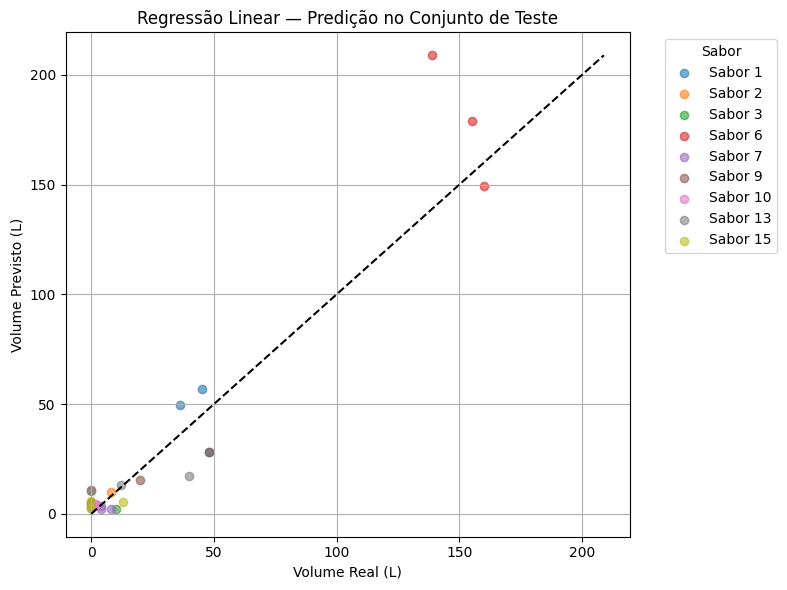

--- Regressão Linear: R² por sabor (TREINO) ---
  Sabor 1: N_treino=12, R²=0.2300
  Sabor 2: N_treino=12, R²=0.2380
  Sabor 3: N_treino=12, R²=0.0009
  Sabor 6: N_treino=12, R²=0.4557
  Sabor 7: N_treino=12, R²=0.0224
  Sabor 9: N_treino=12, R²=0.3790
  Sabor 10: N_treino=12, R²=-0.0031
  Sabor 13: N_treino=12, R²=0.3914
  Sabor 15: N_treino=12, R²=-0.1028

R² global (TREINO, litros reais): 0.9193


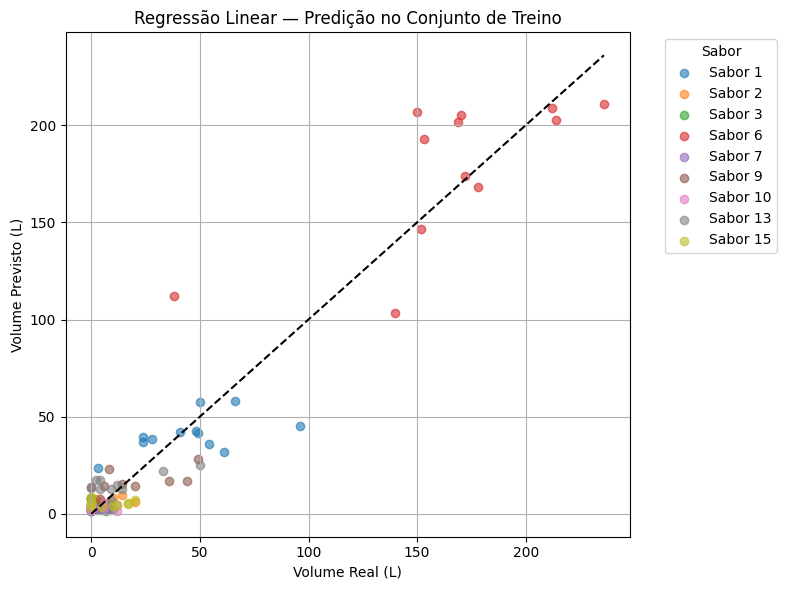

In [ ]:
# ============================================================
# REGRESSÃO LINEAR
# ============================================================
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1) Treino — modelo único, sabor_val como feature
# ------------------------------------------------------------
modelo_lr = LinearRegression()
modelo_lr.fit(X_train, y_train_scaled.ravel())

# ------------------------------------------------------------
# 2) Previsão no conjunto de teste (ainda na escala normalizada)
# ------------------------------------------------------------
pred_scaled = modelo_lr.predict(X_test).reshape(-1, 1)

# ------------------------------------------------------------
# 3) Reverter a normalização para litros reais, sabor por sabor
#    (cada sabor tem seu próprio scaler, então a reversão
#    precisa ser feita separadamente por grupo)
# ------------------------------------------------------------
y_test_real = np.zeros_like(y_test_scaled)
pred_real = np.zeros_like(pred_scaled)

for s in sabores_estabelecidos:
    mask = (df_test['sabor_val'] == s).values
    if mask.sum() == 0:
        continue
    scaler_y = scaler_y_por_sabor[s]
    y_test_real[mask] = scaler_y.inverse_transform(y_test_scaled[mask])
    pred_real[mask] = scaler_y.inverse_transform(pred_scaled[mask])

pred_real = np.clip(pred_real, 0, None)  # volume não pode ser negativo

# ------------------------------------------------------------
# 4) Avaliação — R² por sabor e R² global (em litros reais)
# ------------------------------------------------------------
print("--- Regressão Linear: R² por sabor ---")
for s in sorted(sabores_estabelecidos):
    mask = (df_test['sabor_val'] == s).values
    n = mask.sum()
    if n < 2 or np.std(y_test_real[mask]) == 0:
        print(f"  Sabor {s}: N_teste={n} — R² não confiável com essa amostra")
        continue
    r2 = r2_score(y_test_real[mask], pred_real[mask])
    print(f"  Sabor {s}: N_teste={n}, R²={r2:.4f}")

r2_global = r2_score(y_test_real, pred_real)
print(f"\nR² global (litros reais, todos os sabores estabelecidos juntos): {r2_global:.4f}")

# aviso: o R² global tende a parecer melhor do que os R² individuais
# porque sabores de maior volume (ex: laranja) dominam a variância total.
# O R² por sabor é a métrica mais honesta pra avaliar se o modelo
# realmente aprendeu o padrão de cada sabor individualmente.

# ------------------------------------------------------------
# 5) Gráfico: previsto vs. real, por sabor
# ------------------------------------------------------------
plt.figure(figsize=(8, 6))
for s in sorted(sabores_estabelecidos):
    mask = (df_test['sabor_val'] == s).values
    if mask.sum() == 0:
        continue
    plt.scatter(y_test_real[mask], pred_real[mask], label=f"Sabor {s}", alpha=0.6)

minv = min(y_test_real.min(), pred_real.min())
maxv = max(y_test_real.max(), pred_real.max())
plt.plot([minv, maxv], [minv, maxv], color='black', ls='--')

plt.xlabel('Volume Real (L)')
plt.ylabel('Volume Previsto (L)')
plt.title('Regressão Linear — Predição no Conjunto de Teste')
plt.legend(title='Sabor', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True)
plt.tight_layout()
plt.savefig("linreg-testing.png")
plt.show()

# ============================================================
# REGRESSÃO LINEAR — GRÁFICO DE TREINO
# ============================================================
pred_train_scaled = modelo_lr.predict(X_train).reshape(-1, 1)

y_train_real = np.zeros_like(y_train_scaled)
pred_train_real = np.zeros_like(pred_train_scaled)

for s in sabores_estabelecidos:
    mask = (df_train['sabor_val'] == s).values
    if mask.sum() == 0:
        continue
    scaler_y = scaler_y_por_sabor[s]
    y_train_real[mask] = scaler_y.inverse_transform(y_train_scaled[mask])
    pred_train_real[mask] = scaler_y.inverse_transform(pred_train_scaled[mask])

pred_train_real = np.clip(pred_train_real, 0, None)

print("--- Regressão Linear: R² por sabor (TREINO) ---")
for s in sorted(sabores_estabelecidos):
    mask = (df_train['sabor_val'] == s).values
    n = mask.sum()
    if n < 2 or np.std(y_train_real[mask]) == 0:
        print(f"  Sabor {s}: N_treino={n} — R² não confiável")
        continue
    r2 = r2_score(y_train_real[mask], pred_train_real[mask])
    print(f"  Sabor {s}: N_treino={n}, R²={r2:.4f}")

r2_train_global = r2_score(y_train_real, pred_train_real)
print(f"\nR² global (TREINO, litros reais): {r2_train_global:.4f}")

plt.figure(figsize=(8, 6))
for s in sorted(sabores_estabelecidos):
    mask = (df_train['sabor_val'] == s).values
    if mask.sum() == 0:
        continue
    plt.scatter(y_train_real[mask], pred_train_real[mask], label=f"Sabor {s}", alpha=0.6)

minv = min(y_train_real.min(), pred_train_real.min())
maxv = max(y_train_real.max(), pred_train_real.max())
plt.plot([minv, maxv], [minv, maxv], color='black', ls='--')
plt.xlabel('Volume Real (L)')
plt.ylabel('Volume Previsto (L)')
plt.title('Regressão Linear — Predição no Conjunto de Treino')
plt.legend(title='Sabor', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True)
plt.tight_layout()
plt.savefig("linreg-training.png")
plt.show()


Janelas de treino: (81, 3, 8) | Janelas de teste: (27, 3, 8)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 16)             │         1,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,745 (6.82 KB)

 Trainable params: 1,745 (6.82 KB)

 Non-trainable params: 0 (0.00 B)


--- LSTM: R² por sabor (últimos 3 meses como teste) ---
  Sabor 1: N_teste=3, R²=-0.6879
  Sabor 2: N_teste=3, R²=-23.1395
  Sabor 3: N_teste=3, R²=-0.6715
  Sabor 6: N_teste=3, R²=-232.9586
  Sabor 7: N_teste=3, R²=-2.1867
  Sabor 9: N_teste=3, R²=-1.5711
  Sabor 10: N_teste=3, R²=-0.6451
  Sabor 13: N_teste=3, R²=-5.9989
  Sabor 15: N_teste=3, R²=-1.7130

R² global (LSTM, litros reais): 0.9425


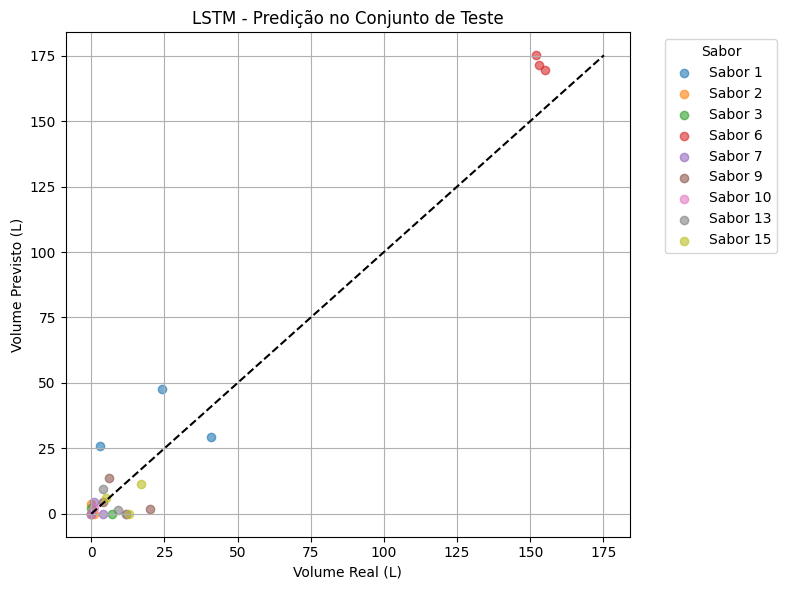

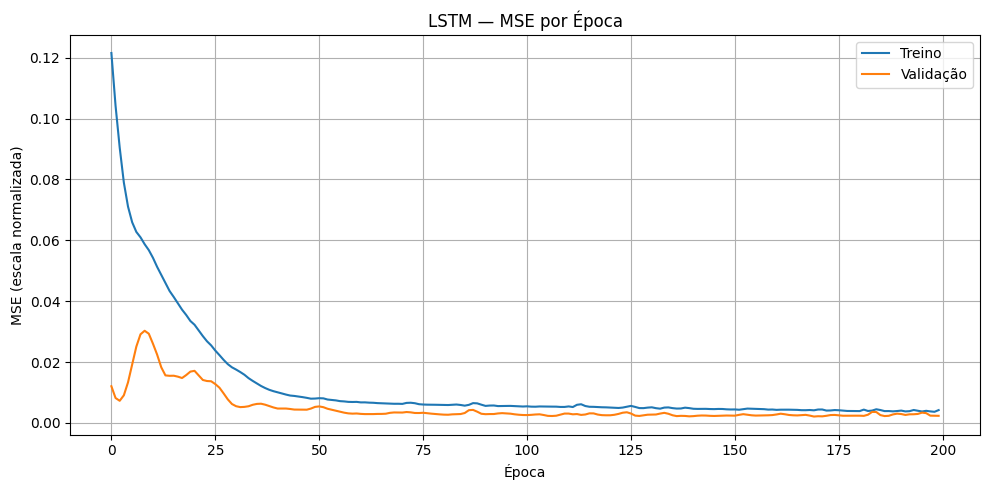

--- LSTM: R² por sabor (TREINO) ---
  Sabor 1: N_treino=9, R²=-0.3183
  Sabor 2: N_treino=9, R²=-1.7058
  Sabor 3: N_treino=9, R²=-12.2832
  Sabor 6: N_treino=9, R²=0.0939
  Sabor 7: N_treino=9, R²=-10.6840
  Sabor 9: N_treino=9, R²=0.5928
  Sabor 10: N_treino=9, R²=-14.1899
  Sabor 13: N_treino=9, R²=0.4313
  Sabor 15: N_treino=9, R²=-0.8949

R² global (TREINO, LSTM, litros reais): 0.9322


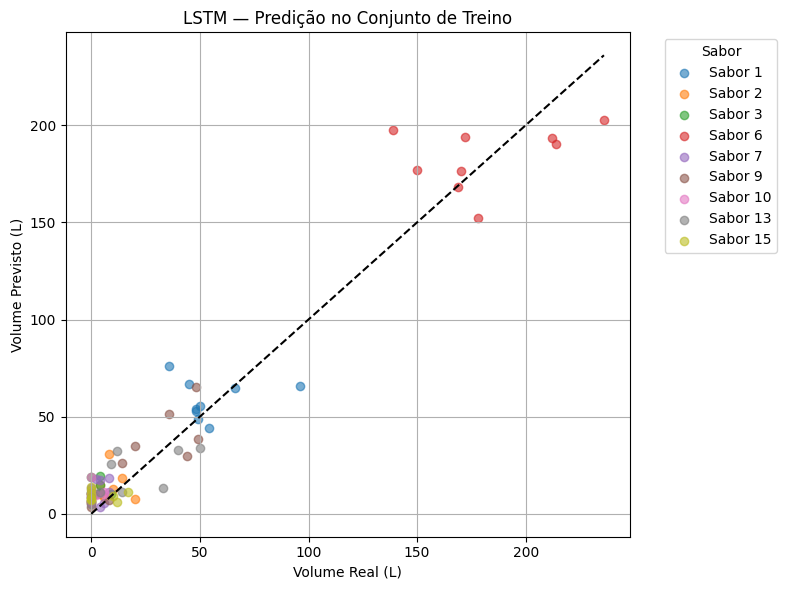

In [ ]:
# ============================================================
# LSTM — PREVISÃO DE VOLUME POR SABOR (SÉRIE TEMPORAL)
# ============================================================
# Diferente da regressão linear, aqui o split NÃO pode ser
# aleatório. A LSTM aprende a partir de sequências de meses
# consecutivos, então o teste precisa ser sempre "o futuro"
# em relação ao treino (senão o modelo aprenderia com dados
# que estão à frente no tempo do que está tentando prever).

import keras
from keras import layers
import tensorflow as tf
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import r2_score
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 0) Preparo: índice temporal contínuo e encoding cíclico do mês
# ------------------------------------------------------------
data_lstm = data_num.copy()
data_lstm['t_idx'] = data_lstm['ano'] * 12 + data_lstm['mes_val']
data_lstm['mes_sin'] = np.sin(2 * np.pi * data_lstm['mes_val'] / 12)
data_lstm['mes_cos'] = np.cos(2 * np.pi * data_lstm['mes_val'] / 12)
data_lstm = data_lstm.sort_values(['sabor_val', 't_idx']).reset_index(drop=True)

FEATURES_LSTM = ['mes_sin', 'mes_cos', 'temperatura', 'dias_uteis',
                  'dias_fim_semana', 'feriado', 'sabor_novo', 'volume_l']
TARGET = 'volume_l'
TARGET_IDX = FEATURES_LSTM.index(TARGET)
JANELA = 3  # meses de histórico usados para prever o mês seguinte

df_estab = data_lstm[data_lstm['sabor_val'].isin(sabores_estabelecidos)].copy()

# split temporal: últimos MESES_TESTE meses = teste, resto = treino
MESES_TESTE = 3
t_max = df_estab['t_idx'].max()
corte = t_max - MESES_TESTE

# scaler ajustado SÓ no período de treino
scaler_lstm = MinMaxScaler()
scaler_lstm.fit(df_estab[df_estab['t_idx'] <= corte][FEATURES_LSTM])

df_estab_scaled = df_estab.copy()
df_estab_scaled[FEATURES_LSTM] = scaler_lstm.transform(df_estab[FEATURES_LSTM])

def montar_sequencias(df_sabor_scaled, janela):
    X, y, t_alvo = [], [], []
    valores = df_sabor_scaled[FEATURES_LSTM].values
    t_idxs = df_sabor_scaled['t_idx'].values
    for i in range(len(valores) - janela):
        X.append(valores[i:i + janela])
        y.append(valores[i + janela, TARGET_IDX])
        t_alvo.append(t_idxs[i + janela])
    return np.array(X), np.array(y), np.array(t_alvo)

X_train_list, y_train_list = [], []
X_test_list, y_test_list = [], []
test_sabor_list = []

for s in sabores_estabelecidos:
    sub = df_estab_scaled[df_estab_scaled['sabor_val'] == s].sort_values('t_idx')
    if len(sub) <= JANELA:
        print(f"  Sabor {s}: histórico insuficiente, pulado")
        continue
    Xs, ys, t_alvo = montar_sequencias(sub, JANELA)
    mask_treino = t_alvo <= corte
    mask_teste = t_alvo > corte
    X_train_list.append(Xs[mask_treino]); y_train_list.append(ys[mask_treino])
    if mask_teste.sum() > 0:
        X_test_list.append(Xs[mask_teste]); y_test_list.append(ys[mask_teste])
        test_sabor_list.extend([s] * mask_teste.sum())

X_train_lstm = np.vstack(X_train_list)
y_train_lstm = np.concatenate(y_train_list)
X_test_lstm = np.vstack(X_test_list)
y_test_lstm = np.concatenate(y_test_list)
test_sabor_arr = np.array(test_sabor_list)

print(f"\nJanelas de treino: {X_train_lstm.shape} | Janelas de teste: {X_test_lstm.shape}")

def build_lstm(janela, n_features):
    model = keras.Sequential([
        layers.Input(shape=(janela, n_features)),
        layers.LSTM(16, activation="tanh"),
        layers.Dense(8, activation="relu"),
        layers.Dense(1)
    ])
    model.compile(loss='mse', optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
                  metrics=['mse', 'mae'])
    return model

model_lstm = build_lstm(JANELA, len(FEATURES_LSTM))
model_lstm.summary()

EPOCHS = 200
history_lstm = model_lstm.fit(X_train_lstm, y_train_lstm, epochs=EPOCHS,
                               verbose=0, validation_split=0.15)

pred_scaled = model_lstm.predict(X_test_lstm, verbose=0).ravel()

def inverse_volume(valores_escalados):
    dummy = np.zeros((len(valores_escalados), len(FEATURES_LSTM)))
    dummy[:, TARGET_IDX] = valores_escalados
    return scaler_lstm.inverse_transform(dummy)[:, TARGET_IDX]

y_test_real = inverse_volume(y_test_lstm)
pred_real = np.clip(inverse_volume(pred_scaled), 0, None)

print(f"\n--- LSTM: R² por sabor (últimos {MESES_TESTE} meses como teste) ---")
for s in sorted(sabores_estabelecidos):
    mask = test_sabor_arr == s
    n = mask.sum()
    if n < 2 or np.std(y_test_real[mask]) == 0:
        print(f"  Sabor {s}: N_teste={n} — R² não confiável")
        continue
    r2 = r2_score(y_test_real[mask], pred_real[mask])
    print(f"  Sabor {s}: N_teste={n}, R²={r2:.4f}")

r2_global = r2_score(y_test_real, pred_real)
print(f"\nR² global (LSTM, litros reais): {r2_global:.4f}")

plt.figure(figsize=(8, 6))
for s in sorted(sabores_estabelecidos):
    mask = test_sabor_arr == s
    if mask.sum() == 0:
        continue
    plt.scatter(y_test_real[mask], pred_real[mask], label=f"Sabor {s}", alpha=0.6)
minv = min(y_test_real.min(), pred_real.min())
maxv = max(y_test_real.max(), pred_real.max())
plt.plot([minv, maxv], [minv, maxv], color='black', ls='--')
plt.xlabel('Volume Real (L)')
plt.ylabel('Volume Previsto (L)')
plt.title('LSTM - Predição no Conjunto de Teste')
plt.legend(title='Sabor', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True)
plt.tight_layout()
plt.savefig("lstm-testing.png")
plt.show()

# ============================================================
# LSTM — GRÁFICOS DE TREINO
# ============================================================

# 1) Curva de MSE por época
plt.figure(figsize=(10, 5))
plt.plot(history_lstm.history['mse'], label='Treino')
if 'val_mse' in history_lstm.history:
    plt.plot(history_lstm.history['val_mse'], label='Validação')
plt.title('LSTM — MSE por Época')
plt.xlabel('Época')
plt.ylabel('MSE (escala normalizada)')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig("lstm-mse-epochs.png")
plt.show()

# 2) Previsto vs. real no conjunto de TREINO
pred_train_scaled = model_lstm.predict(X_train_lstm, verbose=0).ravel()

train_sabor_list = []
for s in sabores_estabelecidos:
    sub = df_estab_scaled[df_estab_scaled['sabor_val'] == s].sort_values('t_idx')
    if len(sub) <= JANELA:
        continue
    _, _, t_alvo = montar_sequencias(sub, JANELA)
    n_treino_sabor = (t_alvo <= corte).sum()
    train_sabor_list.extend([s] * n_treino_sabor)
train_sabor_arr = np.array(train_sabor_list)

y_train_real_lstm = inverse_volume(y_train_lstm)
pred_train_real_lstm = np.clip(inverse_volume(pred_train_scaled), 0, None)

print("--- LSTM: R² por sabor (TREINO) ---")
for s in sorted(sabores_estabelecidos):
    mask = train_sabor_arr == s
    n = mask.sum()
    if n < 2 or np.std(y_train_real_lstm[mask]) == 0:
        print(f"  Sabor {s}: N_treino={n} — R² não confiável")
        continue
    r2 = r2_score(y_train_real_lstm[mask], pred_train_real_lstm[mask])
    print(f"  Sabor {s}: N_treino={n}, R²={r2:.4f}")

r2_train_global_lstm = r2_score(y_train_real_lstm, pred_train_real_lstm)
print(f"\nR² global (TREINO, LSTM, litros reais): {r2_train_global_lstm:.4f}")

plt.figure(figsize=(8, 6))
for s in sorted(sabores_estabelecidos):
    mask = train_sabor_arr == s
    if mask.sum() == 0:
        continue
    plt.scatter(y_train_real_lstm[mask], pred_train_real_lstm[mask], label=f"Sabor {s}", alpha=0.6)

minv = min(y_train_real_lstm.min(), pred_train_real_lstm.min())
maxv = max(y_train_real_lstm.max(), pred_train_real_lstm.max())
plt.plot([minv, maxv], [minv, maxv], color='black', ls='--')
plt.xlabel('Volume Real (L)')
plt.ylabel('Volume Previsto (L)')
plt.title('LSTM — Predição no Conjunto de Treino')
plt.legend(title='Sabor', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True)
plt.tight_layout()
plt.savefig("lstm-training.png")
plt.show()

In [ ]:
def prever_volume(scaler_x, scaler_y_por_sabor, modelos_por_sabor, semana, mes, sabor, temperatura, dias_semana):

    sabor_mapping = {
        'laranja': 1, 'abacaxi': 2, 'abacaxi_com_hortela': 3,
        'laranja_e_couve': 4, 'laranja_e_manga': 5, 'bergamota': 6,
        'melancia': 7, 'maracuja': 8, 'manga': 9, 'morango': 10,
        'limonada': 11, 'limonada_suica': 11, 'goiaba': 12,
        'uva': 13, 'butia': 14
    }

    mes_mapping = {
        'janeiro': 1, 'fevereiro': 2, 'março': 3, 'abril': 4,
        'maio': 5, 'junho': 6, 'julho': 7, 'agosto': 8,
        'setembro': 9, 'outubro': 10, 'novembro': 11, 'dezembro': 12
    }

    sabor_val = sabor_mapping.get(str(sabor).lower()) if isinstance(sabor, str) else sabor
    sabor_mapping_inverso = {}
    for nome, valor in sabor_mapping.items():
        if valor not in sabor_mapping_inverso:
            sabor_mapping_inverso[valor] = nome

    if isinstance(mes, int) and 1 <= mes <= 12:
        mes_val = mes
    else:
        mes_val = mes_mapping.get(str(mes).lower())

    if sabor_val is None:
        raise ValueError(f"Erro: sabor '{sabor}' inválido.")
    if mes_val is None:
        raise ValueError(f"Erro: mês '{mes}' inválido.")

    model = modelos_por_sabor.get(sabor_val)
    if model is None:
        raise ValueError(f"Erro: Nenhum modelo encontrado para o sabor '{sabor_mapping_inverso.get(sabor_val, str(sabor))}'.")

    dias_semana_media = np.mean(dias_semana) if dias_semana else 0
    dias_semana_qtd = len(dias_semana)

    df_features = pd.DataFrame([{
        'semana': semana,
        'mes_val': mes_val,
        'sabor_val': sabor_val,
        'temperatura': temperatura,
        'dias_semana_media': dias_semana_media,
        'dias_semana_qtd': dias_semana_qtd
    }])

    X_scaled = scaler_x.transform(df_features)
    previsao_scaled = model.predict(X_scaled, verbose=0)[0][0]

    scaler_y = scaler_y_por_sabor.get(sabor_val)
    if scaler_y:
        previsao_real = scaler_y.inverse_transform([[previsao_scaled]])[0][0]
    else:
        raise ValueError(f"Erro: Não há scaler Y para o sabor '{sabor}'.")
    if previsao_real < 0:
      previsao_real = 0.0
    nome_sabor = sabor_mapping_inverso.get(sabor_val, str(sabor))
    print(f"Previsão de volume ({nome_sabor}, semana {semana}/{mes}): {previsao_real:.2f} litros")
    return previsao_real

def semana_do_mes(data):
    ano = data.year
    mes = data.month
    dia = data.day

    cal = calendar.monthcalendar(ano, mes)

    for semana_idx, semana in enumerate(cal, start=1):
        if dia in semana:
            return semana_idx

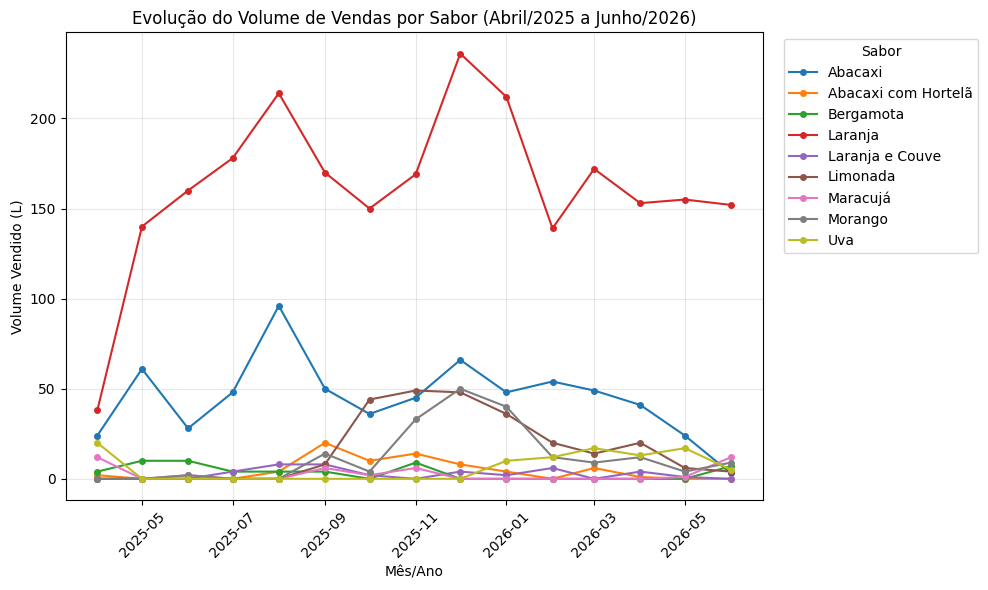

In [ ]:
import matplotlib.pyplot as plt

sabor_nomes = {1:'Abacaxi', 2:'Abacaxi com Hortelã', 3:'Bergamota', 6:'Laranja',
               7:'Laranja e Couve', 9:'Limonada', 10:'Maracujá', 13:'Morango', 15:'Uva'}

# cria uma coluna de data real, para o eixo x ficar em ordem cronológica correta
data_num['data_ref'] = pd.to_datetime(
    data_num['ano'].astype(str) + '-' + data_num['mes_val'].astype(str) + '-01'
)

plt.figure(figsize=(10, 6))
for s in sorted(sabores_estabelecidos):
    sub = data_num[data_num['sabor_val'] == s].sort_values('data_ref')
    plt.plot(sub['data_ref'], sub['volume_l'], marker='o', markersize=4,
              label=sabor_nomes[s], linewidth=1.5)

plt.xlabel('Mês/Ano')
plt.ylabel('Volume Vendido (L)')
plt.title('Evolução do Volume de Vendas por Sabor (Abril/2025 a Junho/2026)')
plt.legend(title='Sabor', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.grid(True, alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("evolucao_volume_sabores.png", dpi=150)
plt.show()

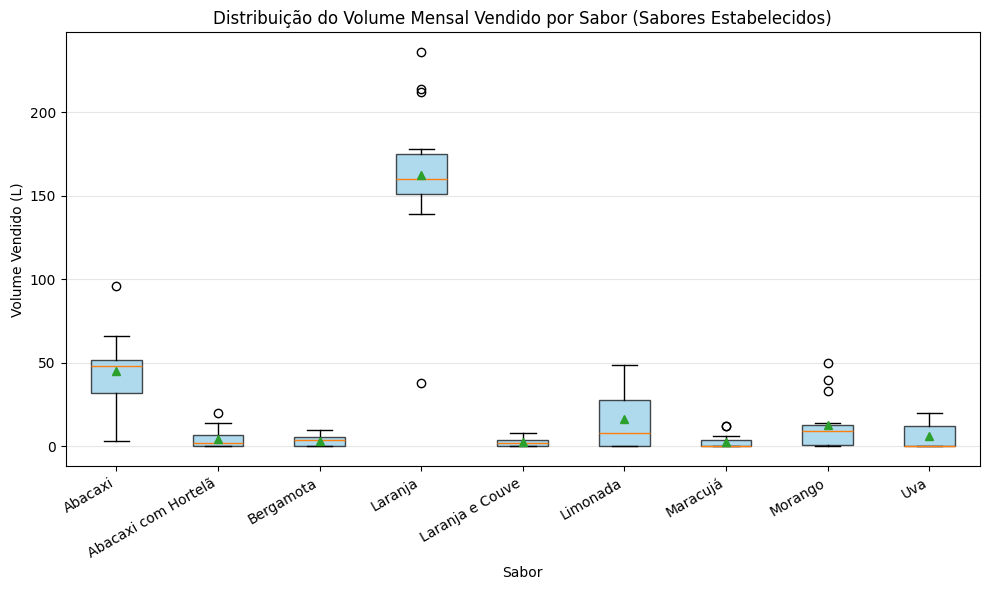

In [ ]:
import matplotlib.pyplot as plt

sabor_nomes = {1:'Abacaxi', 2:'Abacaxi com Hortelã', 3:'Bergamota', 6:'Laranja',
               7:'Laranja e Couve', 9:'Limonada', 10:'Maracujá', 13:'Morango', 15:'Uva'}

dados_boxplot = [data_num[data_num['sabor_val'] == s]['volume_l'].values
                  for s in sorted(sabores_estabelecidos)]
rotulos = [sabor_nomes[s] for s in sorted(sabores_estabelecidos)]

plt.figure(figsize=(10, 6))
bp = plt.boxplot(dados_boxplot, tick_labels=rotulos, patch_artist=True, showmeans=True)
for patch in bp['boxes']:
    patch.set_facecolor('#8ecae6')
    patch.set_alpha(0.7)

plt.xlabel('Sabor')
plt.ylabel('Volume Vendido (L)')
plt.title('Distribuição do Volume Mensal Vendido por Sabor (Sabores Estabelecidos)')
plt.xticks(rotation=30, ha='right')
plt.grid(True, axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig("boxplot_volume_sabores.png", dpi=150)
plt.show()